# NYC Rodent Inspection - Model Comparison: Random Forest vs Gradient Boosted Trees

### Prerequisites

- The raw CSV at `../data/raw/Rodent_Inspection.csv`
- Java 11+ available to PySpark
- ~10–20 minutes of compute on a laptop


## 0: Environment setup

In [1]:
# ── Java + Hadoop env (mirrors the pipeline scripts) ──────────────────────────
import os
os.environ["JAVA_HOME"] = "/opt/homebrew/opt/java/libexec/openjdk.jdk/Contents/Home"
os.environ["HADOOP_HOME"] = "/opt/homebrew/opt/hadoop/libexec"
os.environ["hadoop.home.dir"] = os.environ["HADOOP_HOME"]
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
# Reused throughout
RAW_CSV          = "../../data/raw/Rodent_Inspection_20260502.csv"
PROCESSED_PATH   = "../../data/processed/rodent_inspections.parquet"
FEATURES_PATH    = "../../data/features/rodent_features.parquet"
MODEL_OUT        = "../../models/rodent_classifier_nb"           # separate from script's output
PREDS_OUT        = "../../data/predictions/test_predictions_nb.parquet"
print("Env configured.")


Env configured.


In [2]:
# ── One Spark session reused by all three stages ──────────────────────────────
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("RodentModelComparisonNotebook")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.local.dir", "/Users/akashweb/spark-temp")
    .config("spark.hadoop.fs.permissions", "false")
    .config("spark.hadoop.mapreduce.fileoutputcommitter.algorithm.version", "1")
    .config("spark.hadoop.fs.file.impl", "org.apache.hadoop.fs.RawLocalFileSystem")
    .config("spark.hadoop.fs.AbstractFileSystem.file.impl", "org.apache.hadoop.fs.local.LocalFs")
    .config("spark.hadoop.home.dir", "/opt/homebrew/opt/hadoop/libexec")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Spark session up:", spark.version)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/05 16:57:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/05/05 16:57:55 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark session up: 4.0.0


---

## 1: ETL (from `process_rodent_data.py`)

Reads raw CSV -> enforces 25-field schema -> parses dates with fallback -> drops nulls -> deduplicates -> writes Parquet partitioned by `year` and `BOROUGH`.

The schema is enforced rather than inferred because Spark schema inference on a 1 GB CSV is slow and unreliable. The date parser tries `MM/dd/yyyy hh:mm:ss a` first; if more than 80% of values come back null, it falls back to `MM/dd/yyyy` - DOHMH used the shorter format in earlier years.


In [3]:
# ── Schema (verbatim from process_rodent_data.py) ────────────────────────────
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

SCHEMA = StructType([
    StructField("INSPECTION_TYPE",             StringType(),  True),
    StructField("JOB_TICKET_OR_WORK_ORDER_ID", StringType(),  True),
    StructField("JOB_ID",                      StringType(),  True),
    StructField("JOB_PROGRESS",                IntegerType(), True),
    StructField("BBL",                         StringType(),  True),
    StructField("BORO_CODE",                   IntegerType(), True),
    StructField("BLOCK",                       IntegerType(), True),
    StructField("LOT",                         IntegerType(), True),
    StructField("HOUSE_NUMBER",                StringType(),  True),
    StructField("STREET_NAME",                 StringType(),  True),
    StructField("ZIP_CODE",                    IntegerType(), True),
    StructField("X_COORD",                     DoubleType(),  True),
    StructField("Y_COORD",                     DoubleType(),  True),
    StructField("LATITUDE",                    DoubleType(),  True),
    StructField("LONGITUDE",                   DoubleType(),  True),
    StructField("BOROUGH",                     StringType(),  True),
    StructField("INSPECTION_DATE",             StringType(),  True),
    StructField("RESULT",                      StringType(),  True),
    StructField("APPROVED_DATE",               StringType(),  True),
    StructField("LOCATION",                    StringType(),  True),
    StructField("COMMUNITY BOARD",             IntegerType(), True),
    StructField("COUNCIL DISTRICT",            IntegerType(), True),
    StructField("CENSUS TRACT",                StringType(),  True),
    StructField("BIN",                         IntegerType(), True),
    StructField("NTA",                         StringType(),  True),
])
print(f"Schema declared: {len(SCHEMA.fields)} fields")


Schema declared: 25 fields


In [4]:
# ── Read CSV with declared schema, parse timestamps, fall back if needed ─────
from pyspark.sql.functions import to_timestamp, col, year, month

df = spark.read.schema(SCHEMA).option("header", True).csv(RAW_CSV)

df = (
    df
    .withColumn("inspection_ts", to_timestamp(col("INSPECTION_DATE"), "MM/dd/yyyy hh:mm:ss a"))
    .withColumn("approved_ts",   to_timestamp(col("APPROVED_DATE"),   "MM/dd/yyyy hh:mm:ss a"))
)

null_fraction = df.filter(col("inspection_ts").isNull()).count() / df.count()
print(f"Null fraction with full timestamp format: {null_fraction:.3f}")

if null_fraction > 0.8:
    print("Falling back to MM/dd/yyyy format...")
    df = (
        df.drop("inspection_ts", "approved_ts")
          .withColumn("inspection_ts", to_timestamp(col("INSPECTION_DATE"), "MM/dd/yyyy"))
          .withColumn("approved_ts",   to_timestamp(col("APPROVED_DATE"),   "MM/dd/yyyy"))
    )

df.select("INSPECTION_DATE", "inspection_ts").show(5, truncate=False)


Null fraction with full timestamp format: 0.000
+----------------------+-------------------+
|INSPECTION_DATE       |inspection_ts      |
+----------------------+-------------------+
|08/30/2010 03:23:11 PM|2010-08-30 15:23:11|
|08/18/2011 12:05:54 PM|2011-08-18 12:05:54|
|10/10/2018 12:57:02 PM|2018-10-10 12:57:02|
|02/07/2019 12:48:34 PM|2019-02-07 12:48:34|
|06/20/2019 04:02:23 PM|2019-06-20 16:02:23|
+----------------------+-------------------+
only showing top 5 rows


In [5]:
# ── Clean: drop bad dates, deduplicate, add year/month, write Parquet ────────
df_clean = (
    df
    .filter(col("inspection_ts").isNotNull())
    .dropDuplicates(["JOB_TICKET_OR_WORK_ORDER_ID", "inspection_ts"])
    .withColumn("year",  year(col("inspection_ts")))
    .withColumn("month", month(col("inspection_ts")))
)

print(f"Rows after cleaning: {df_clean.count():,}")

df_clean.write.mode("overwrite").partitionBy("year", "BOROUGH").parquet(PROCESSED_PATH)
print(f"Parquet written to: {PROCESSED_PATH}")


Rows after cleaning: 2,032,107


26/05/05 16:58:14 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Parquet written to: ../../data/processed/rodent_inspections.parquet


---

## 2: Feature engineering

Aggregates the cleaned inspections to one row per **(ZIP_CODE, year, month)**, then derives temporal features that describe each ZIP's *recent history* without leaking information from the month being predicted.

**Three feature families:**

| Family | Columns | Window |
|---|---|---|
| Lag | `lag1/2/3_rat_rate`, `lag1_total`, `lag1_rat_count` | Strictly prior months |
| Rolling | `rolling3/6_avg_rat_rate`, `rolling3_rat_count`, `rolling3_total` | Trailing 3- or 6-month windows, current month excluded |
| Expanding | `hist_avg_rat_rate` | All months strictly before the current one |
| Seasonal | `quarter`, `is_summer`, `is_winter` | Calendar |

Every window definition uses `rowsBetween(..., -1)`. The current month is never included. **No leakage.**

The binary label is `1 if rat_positive_rate >= 20% else 0` - the threshold sits between the pre-2020 baseline (~13%) and post-2020 baseline (~33%) for reasonably balanced classes.


In [6]:
# ── Load processed parquet, derive rat_positive flag ─────────────────────────
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import IntegerType, DoubleType
from pyspark.ml.feature import StringIndexer

RAT_POSITIVE     = ("Rat Activity", "Bait applied")
LABEL_THRESHOLD  = 20.0

df_proc = spark.read.parquet(PROCESSED_PATH)
df_proc = df_proc.withColumn(
    "rat_positive",
    F.when(F.col("RESULT").isin(*RAT_POSITIVE), 1).otherwise(0),
)

# Validity filter
df_proc = df_proc.filter(
    F.col("ZIP_CODE").isNotNull()
    & F.col("BOROUGH").isNotNull()
    & F.col("year").isNotNull()
    & F.col("month").isNotNull()
    & (F.col("ZIP_CODE") > 0)
)
print(f"Rows after validity filter: {df_proc.count():,}")


Rows after validity filter: 2,017,101


In [7]:
# ── Stable borough lookup per ZIP (handles zips that straddle boroughs) ──────
w_boro = Window.partitionBy("ZIP_CODE").orderBy(F.col("boro_cnt").desc())
borough_lookup = (
    df_proc.groupBy("ZIP_CODE", "BOROUGH")
    .agg(F.count("*").alias("boro_cnt"))
    .withColumn("rn", F.row_number().over(w_boro))
    .filter(F.col("rn") == 1)
    .drop("rn", "boro_cnt")
)

# ── Aggregate to (ZIP_CODE, year, month) ─────────────────────────────────────
agg = (
    df_proc.groupBy("ZIP_CODE", "year", "month")
    .agg(
        F.count("*").alias("total_inspections"),
        F.sum("rat_positive").alias("rat_positive_count"),
    )
    .withColumn(
        "rat_positive_rate",
        (F.col("rat_positive_count") / F.col("total_inspections") * 100.0).cast(DoubleType()),
    )
    .join(borough_lookup, on="ZIP_CODE", how="left")
)

# Monotonic time index for window ordering across year boundaries
agg = agg.withColumn(
    "time_idx",
    (F.col("year") * 12 + F.col("month")).cast(IntegerType()),
)

print(f"Rows after aggregation: {agg.count():,}")


Rows after aggregation: 31,543


In [8]:
# ── Seasonal features ─────────────────────────────────────────────────────────
agg = (
    agg
    .withColumn("quarter",   F.ceil(F.col("month") / 3).cast(IntegerType()))
    .withColumn("is_summer", F.when(F.col("month").between(5, 9), 1).otherwise(0).cast(IntegerType()))
    .withColumn("is_winter", F.when(F.col("month").isin(12, 1, 2), 1).otherwise(0).cast(IntegerType()))
)

# ── Window definitions: all strictly EXCLUDE the current row ─────────────────
w_zip      = Window.partitionBy("ZIP_CODE").orderBy("time_idx")
w_zip_3    = Window.partitionBy("ZIP_CODE").orderBy("time_idx").rowsBetween(-3, -1)
w_zip_6    = Window.partitionBy("ZIP_CODE").orderBy("time_idx").rowsBetween(-6, -1)
w_zip_hist = (
    Window.partitionBy("ZIP_CODE")
    .orderBy("time_idx")
    .rowsBetween(Window.unboundedPreceding, -1)
)

# ── Lag features ─────────────────────────────────────────────────────────────
agg = (
    agg
    .withColumn("lag1_rat_rate",  F.lag("rat_positive_rate", 1).over(w_zip))
    .withColumn("lag2_rat_rate",  F.lag("rat_positive_rate", 2).over(w_zip))
    .withColumn("lag3_rat_rate",  F.lag("rat_positive_rate", 3).over(w_zip))
    .withColumn("lag1_total",     F.lag("total_inspections",  1).over(w_zip))
    .withColumn("lag1_rat_count", F.lag("rat_positive_count", 1).over(w_zip))
)

# ── Rolling + expanding features ─────────────────────────────────────────────
agg = (
    agg
    .withColumn("rolling3_avg_rat_rate", F.avg("rat_positive_rate").over(w_zip_3))
    .withColumn("rolling6_avg_rat_rate", F.avg("rat_positive_rate").over(w_zip_6))
    .withColumn("rolling3_rat_count",    F.sum("rat_positive_count").over(w_zip_3))
    .withColumn("rolling3_total",        F.sum("total_inspections").over(w_zip_3))
    .withColumn("hist_avg_rat_rate",     F.avg("rat_positive_rate").over(w_zip_hist))
)

# ── Encode borough ───────────────────────────────────────────────────────────
borough_indexer = StringIndexer(inputCol="BOROUGH", outputCol="borough_idx", handleInvalid="keep")
agg = borough_indexer.fit(agg).transform(agg)

# ── Binary label ─────────────────────────────────────────────────────────────
agg = agg.withColumn(
    "label",
    F.when(F.col("rat_positive_rate") >= LABEL_THRESHOLD, 1).otherwise(0).cast(IntegerType()),
)

print("Features computed.")


Features computed.


In [9]:
# ── Drop warm-up rows (first 1–3 months per ZIP have null lag/rolling) ───────
required_cols = [
    "lag1_rat_rate", "lag2_rat_rate", "lag3_rat_rate",
    "rolling3_avg_rat_rate", "hist_avg_rat_rate",
]
agg_clean = agg.dropna(subset=required_cols)

n_total = agg.count()
n_clean = agg_clean.count()
print(f"Rows before warm-up drop : {n_total:,}")
print(f"Rows after  warm-up drop : {n_clean:,}  ({n_total - n_clean:,} dropped)")

print("\nLabel distribution:")
agg_clean.groupBy("label").count().orderBy("label").show()

# Persist for stage 3
agg_clean.write.mode("overwrite").parquet(FEATURES_PATH)
print(f"Features written to: {FEATURES_PATH}")


Rows before warm-up drop : 31,543
Rows after  warm-up drop : 30,872  (671 dropped)

Label distribution:


+-----+-----+
|label|count|
+-----+-----+
|    0|14988|
|    1|15884|
+-----+-----+



Features written to: ../../data/features/rodent_features.parquet


---

## 3: Train both classifiers

Two classifiers, **identical input features**, **identical train/test split**:

- **Random Forest** - 100 trees, depth 10
- **Gradient Boosted Trees** - 50 iterations, depth 8

The split is **temporal**, not random:
- Train: 2009 – 2022
- Test: 2023 – 2025

A random split would let the model see future months for the same ZIP during training, producing optimistic metrics that wouldn't hold in a real forecasting deployment. Temporal holdout is the only honest setup for time-series prediction.

The 17 features deliberately exclude `total_inspections`, `rat_positive_count`, and `rat_positive_rate` - those are computed from the very month being predicted and would leak the answer.


In [10]:
# ── Feature columns (verbatim from train_classifier.py) ──────────────────────
FEATURE_COLS = [
    # Temporal / seasonal
    "month", "year", "quarter", "is_summer", "is_winter",
    # Geographic
    "borough_idx", "zip_code_num",
    # Lag rates (prior 1–3 months)
    "lag1_rat_rate", "lag2_rat_rate", "lag3_rat_rate",
    # Lag volume
    "lag1_total", "lag1_rat_count",
    # Rolling trends
    "rolling3_avg_rat_rate", "rolling6_avg_rat_rate",
    "rolling3_rat_count", "rolling3_total",
    # Long-run baseline
    "hist_avg_rat_rate",
]
print(f"Feature count: {len(FEATURE_COLS)}")

TRAIN_END_YEAR  = 2022
TEST_START_YEAR = 2023


Feature count: 17


In [11]:
# ── Load features, prep types ────────────────────────────────────────────────
df_f = spark.read.parquet(FEATURES_PATH)

df_f = df_f.withColumn("zip_code_num", F.col("ZIP_CODE").cast(DoubleType()))

# rolling6 can be null for ZIPs with only 3–5 months of history; fall back to rolling3
df_f = df_f.withColumn(
    "rolling6_avg_rat_rate",
    F.coalesce(F.col("rolling6_avg_rat_rate"), F.col("rolling3_avg_rat_rate")),
)

# MLlib needs DoubleType for all features
for c in FEATURE_COLS:
    df_f = df_f.withColumn(c, F.col(c).cast(DoubleType()))
df_f = df_f.withColumn("label", F.col("label").cast(DoubleType()))

# Temporal split
train_df = df_f.filter(F.col("year") <= TRAIN_END_YEAR)
test_df  = df_f.filter(F.col("year") >= TEST_START_YEAR)

print(f"Train rows : {train_df.count():,}  (≤ {TRAIN_END_YEAR})")
print(f"Test  rows : {test_df.count():,}  ({TEST_START_YEAR}–2025)")


Train rows : 24,439  (≤ 2022)
Test  rows : 6,433  (2023–2025)


In [12]:
# ── Build pipelines: VectorAssembler + classifier ────────────────────────────
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier, GBTClassifier

assembler = VectorAssembler(
    inputCols=FEATURE_COLS,
    outputCol="features",
    handleInvalid="skip",
)

rf = RandomForestClassifier(
    featuresCol="features", labelCol="label",
    numTrees=100, maxDepth=10, seed=42,
)
gbt = GBTClassifier(
    featuresCol="features", labelCol="label",
    maxIter=50, maxDepth=8, seed=42,
)

print("Training Random Forest...")
rf_model  = Pipeline(stages=[assembler, rf]).fit(train_df)
rf_preds  = rf_model.transform(test_df)
print("✓ RF done")

print("Training Gradient Boosted Trees...")
gbt_model = Pipeline(stages=[assembler, gbt]).fit(train_df)
gbt_preds = gbt_model.transform(test_df)
print("✓ GBT done")


Training Random Forest...


26/05/05 16:59:33 WARN DAGScheduler: Broadcasting large task binary with size 1860.6 KiB
26/05/05 16:59:37 WARN DAGScheduler: Broadcasting large task binary with size 3.4 MiB
26/05/05 16:59:41 WARN DAGScheduler: Broadcasting large task binary with size 6.1 MiB
26/05/05 16:59:43 WARN DAGScheduler: Broadcasting large task binary with size 1498.1 KiB
26/05/05 16:59:46 WARN DAGScheduler: Broadcasting large task binary with size 10.3 MiB
26/05/05 16:59:48 WARN DAGScheduler: Broadcasting large task binary with size 2.1 MiB


✓ RF done
Training Gradient Boosted Trees...


26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1009.8 KiB
26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1012.4 KiB
26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1012.8 KiB
26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1013.9 KiB
26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1014.6 KiB
26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1017.0 KiB
26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1021.6 KiB
26/05/05 17:00:01 WARN DAGScheduler: Broadcasting large task binary with size 1030.4 KiB
26/05/05 17:00:02 WARN DAGScheduler: Broadcasting large task binary with size 1046.0 KiB
26/05/05 17:00:02 WARN DAGScheduler: Broadcasting large task binary with size 1048.4 KiB
26/05/05 17:00:02 WARN DAGScheduler: Broadcasting large task binary with size 1048.9 KiB
26/05/05 17:00:02 WAR

✓ GBT done


---

## 4: Side-by-side metrics

The same `evaluate()` helper from `train_classifier.py` - five metrics on the held-out 2023–2025 test set.

| Metric | What it tells us |
|---|---|
| **AUC-ROC** | How well the model separates classes across all thresholds. The selection criterion in the pipeline. |
| **Accuracy** | Fraction of predictions that match the label. Sensitive to class imbalance. |
| **F1** | Harmonic mean of precision and recall. Balanced view. |
| **Precision (weighted)** | Of flagged ZIPs, what fraction were actually high-risk. |
| **Recall (weighted)** | Of truly high-risk ZIPs, what fraction we caught. |


In [13]:
# ── Evaluator (verbatim from train_classifier.py) ────────────────────────────
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator,
)

def evaluate(predictions, label="label"):
    bin_eval     = BinaryClassificationEvaluator(labelCol=label, rawPredictionCol="rawPrediction", metricName="areaUnderROC")
    mc_eval_acc  = MulticlassClassificationEvaluator(labelCol=label, predictionCol="prediction", metricName="accuracy")
    mc_eval_f1   = MulticlassClassificationEvaluator(labelCol=label, predictionCol="prediction", metricName="f1")
    mc_eval_prec = MulticlassClassificationEvaluator(labelCol=label, predictionCol="prediction", metricName="weightedPrecision")
    mc_eval_rec  = MulticlassClassificationEvaluator(labelCol=label, predictionCol="prediction", metricName="weightedRecall")
    return {
        "auc_roc":   round(bin_eval.evaluate(predictions),    4),
        "accuracy":  round(mc_eval_acc.evaluate(predictions), 4),
        "f1":        round(mc_eval_f1.evaluate(predictions),  4),
        "precision": round(mc_eval_prec.evaluate(predictions), 4),
        "recall":    round(mc_eval_rec.evaluate(predictions),  4),
    }

rf_metrics  = evaluate(rf_preds)
gbt_metrics = evaluate(gbt_preds)

import pandas as pd
metrics_df = pd.DataFrame({"Random Forest": rf_metrics, "GBT": gbt_metrics})
metrics_df["Δ (RF − GBT)"] = (metrics_df["Random Forest"] - metrics_df["GBT"]).round(4)
metrics_df.style.format("{:.4f}").background_gradient(subset=["Δ (RF − GBT)"], cmap="RdYlGn")


26/05/05 17:00:13 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/05/05 17:00:14 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/05/05 17:00:16 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/05/05 17:00:17 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/05/05 17:00:18 WARN DAGScheduler: Broadcasting large task binary with size 7.0 MiB
26/05/05 17:00:18 WARN DAGScheduler: Broadcasting large task binary with size 1883.7 KiB
26/05/05 17:00:18 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/05/05 17:00:18 WARN DAGScheduler: Broadcasting large task binary with size 1896.5 KiB
26/05/05 17:00:19 WARN DAGScheduler: Broadcasting large task binary with size 1896.5 KiB
26/05/05 17:00:19 WARN DAGScheduler: Broadcasting large task binary with size 1896.5 KiB
26/05/05 17:00:19 WARN DAGScheduler: Broadcasting large task binary with size 1896.5 KiB


,Random Forest,GBT,Δ (RF − GBT)
auc_roc,0.8715,0.8476,0.0239
accuracy,0.8271,0.8133,0.0138
f1,0.8242,0.8098,0.0144
precision,0.8230,0.8083,0.0147
recall,0.8271,0.8133,0.0138


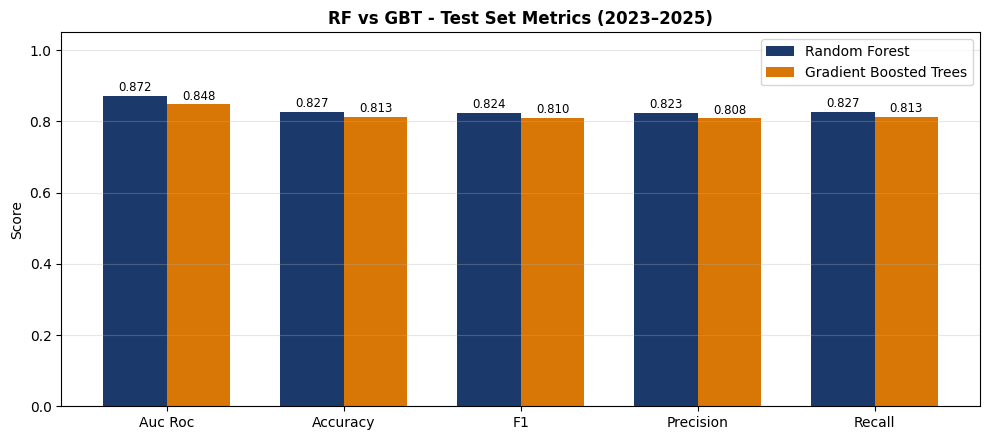

In [14]:
# ── Bar chart for visual comparison ──────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np

metrics_names = ["auc_roc", "accuracy", "f1", "precision", "recall"]
rf_vals  = [rf_metrics[m]  for m in metrics_names]
gbt_vals = [gbt_metrics[m] for m in metrics_names]

x = np.arange(len(metrics_names))
w = 0.36

fig, ax = plt.subplots(figsize=(10, 4.5))
b1 = ax.bar(x - w/2, rf_vals,  w, label="Random Forest",         color="#1B3A6B")
b2 = ax.bar(x + w/2, gbt_vals, w, label="Gradient Boosted Trees", color="#D97706")

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.005, f"{h:.3f}",
                ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels([m.replace("_", " ").title() for m in metrics_names])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("RF vs GBT - Test Set Metrics (2023–2025)", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


---

## 5: ROC curves

AUC-ROC is the single number that drives model selection in `train_classifier.py`. The ROC curve unpacks that number - it plots the true positive rate against the false positive rate across every possible decision threshold.

The closer a curve hugs the top-left corner, the better the model separates high-risk from low-risk ZIPs. A diagonal line is random guessing. A larger area under the curve means more reliable ranking - for any high-risk and low-risk pair, the model is more likely to score the high-risk one higher.


26/05/05 17:01:53 WARN DAGScheduler: Broadcasting large task binary with size 6.9 MiB
26/05/05 17:01:54 WARN DAGScheduler: Broadcasting large task binary with size 1868.4 KiB


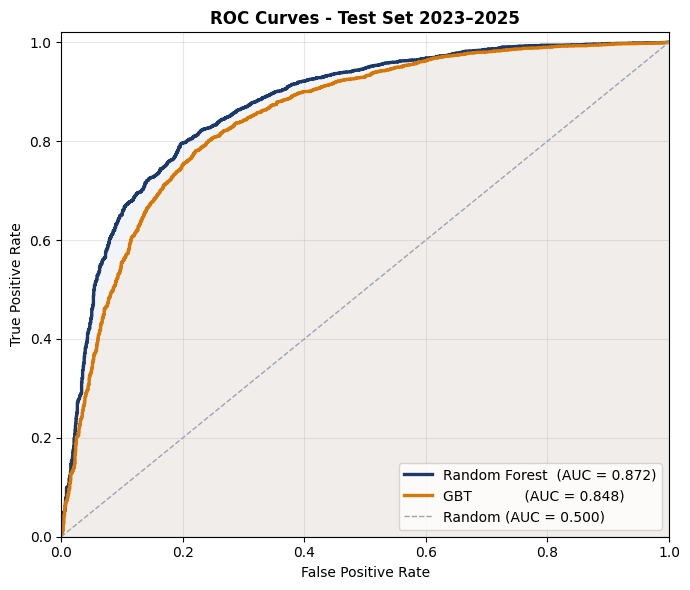


Winner by AUC-ROC: Random Forest  (margin: 0.0239)


In [16]:
# ── Pull predictions to pandas and compute ROC ───────────────────────────────
from pyspark.ml.functions import vector_to_array
def roc_curve(y_true, y_score):
    y_true, y_score = np.array(y_true), np.array(y_score)
    thresholds = np.sort(np.unique(y_score))[::-1]
    pos, neg = (y_true == 1).sum(), (y_true == 0).sum()
    tpr, fpr = [0.0], [0.0]
    for t in thresholds:
        pred = (y_score >= t).astype(int)
        tp = ((pred == 1) & (y_true == 1)).sum()
        fp = ((pred == 1) & (y_true == 0)).sum()
        tpr.append(tp / pos if pos else 0)
        fpr.append(fp / neg if neg else 0)
    return np.array(fpr + [1.0]), np.array(tpr + [1.0]), np.concatenate([[thresholds[0]+1], thresholds])

def auc(fpr, tpr):
    return float(np.trapezoid(tpr, fpr))

def to_pandas_with_proba(preds):
    return (
        preds.withColumn("p1", vector_to_array("probability")[1])
             .select("label", "prediction", "p1", "year", "month")
             .toPandas()
    )

rf_pdf  = to_pandas_with_proba(rf_preds)
gbt_pdf = to_pandas_with_proba(gbt_preds)

rf_fpr,  rf_tpr,  _ = roc_curve(rf_pdf["label"],  rf_pdf["p1"])
gbt_fpr, gbt_tpr, _ = roc_curve(gbt_pdf["label"], gbt_pdf["p1"])
rf_auc  = auc(rf_fpr,  rf_tpr)
gbt_auc = auc(gbt_fpr, gbt_tpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(rf_fpr,  rf_tpr,  color="#1B3A6B", lw=2.4, label=f"Random Forest  (AUC = {rf_auc:.3f})")
ax.plot(gbt_fpr, gbt_tpr, color="#D97706", lw=2.4, label=f"GBT            (AUC = {gbt_auc:.3f})")
ax.plot([0, 1], [0, 1], color="#9CA3AF", lw=1, ls="--", label="Random (AUC = 0.500)")
ax.fill_between(rf_fpr,  rf_tpr,  alpha=0.05, color="#1B3A6B")
ax.fill_between(gbt_fpr, gbt_tpr, alpha=0.05, color="#D97706")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - Test Set 2023–2025", fontweight="bold")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

print(f"\nWinner by AUC-ROC: {'Random Forest' if rf_auc >= gbt_auc else 'GBT'}  "
      f"(margin: {abs(rf_auc - gbt_auc):.4f})")


---

## 6: Confusion matrices

ROC tells us about ranking quality across thresholds. Confusion matrices show what actually happens at the **default 0.5 threshold** - the predictions the dashboard would actually display.

Reading the cells:
- **TP / TN**: model predicted correctly
- **FP** (false positive): model flagged a ZIP as high-risk when it wasn't - wasted intervention
- **FN** (false negative): model missed an actual high-risk ZIP - uncaught infestation

The cost of FP and FN is asymmetric in the real-world deployment. A missed high-risk ZIP is operationally worse than a false alarm.


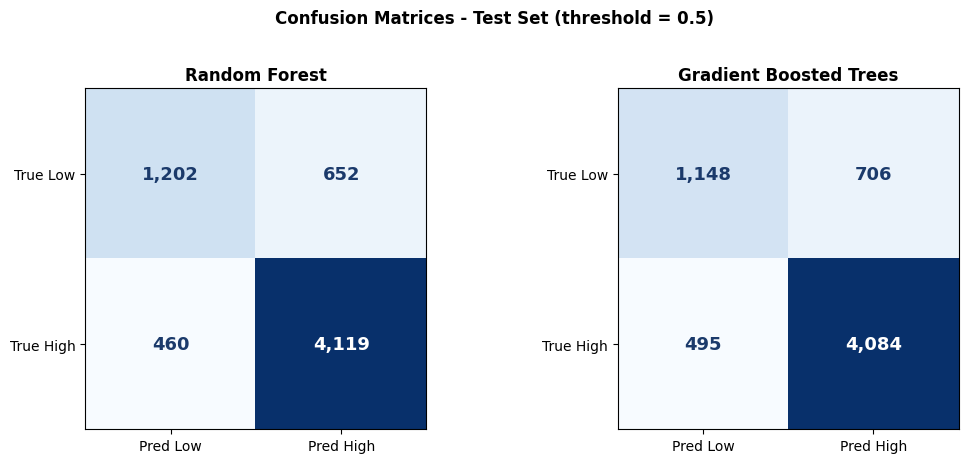

,Random Forest,GBT
Recall (TPR),0.900,0.892
Specificity,0.648,0.619
Precision,0.863,0.853
FPR (false alarm),0.352,0.381
FNR (miss rate),0.100,0.108


In [17]:
# ── Confusion matrices side by side ──────────────────────────────────────────
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    cm = np.zeros((2, 2), dtype=int)
    for i in range(2):
        for j in range(2):
            cm[i, j] = ((y_true == i) & (y_pred == j)).sum()
    return cm

def plot_cm(ax, df, title):
    cm = confusion_matrix(df["label"], df["prediction"])
    im = ax.imshow(cm, cmap="Blues", aspect="equal")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i,j]:,}",
                    ha="center", va="center", fontsize=13,
                    color="white" if cm[i,j] > cm.max()/2 else "#1B3A6B",
                    fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred Low", "Pred High"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["True Low", "True High"])
    ax.set_title(title, fontweight="bold")
    return cm

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_rf  = plot_cm(axes[0], rf_pdf,  "Random Forest")
cm_gbt = plot_cm(axes[1], gbt_pdf, "Gradient Boosted Trees")
plt.suptitle("Confusion Matrices - Test Set (threshold = 0.5)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Derived rates
def rates(cm):
    tn, fp, fn, tp = cm.ravel()
    return {
        "Recall (TPR)":  tp / (tp + fn) if (tp + fn) else 0,
        "Specificity":   tn / (tn + fp) if (tn + fp) else 0,
        "Precision":     tp / (tp + fp) if (tp + fp) else 0,
        "FPR (false alarm)":  fp / (fp + tn) if (fp + tn) else 0,
        "FNR (miss rate)":    fn / (fn + tp) if (fn + tp) else 0,
    }

rates_df = pd.DataFrame({"Random Forest": rates(cm_rf), "GBT": rates(cm_gbt)})
rates_df.style.format("{:.3f}").background_gradient(axis=1, cmap="RdYlGn")


---

## 7: Feature importances

Both tree ensembles expose `featureImportances` - a vector showing how much each input contributed to splits across all trees, weighted by the impurity reduction it produced. Higher value = more useful for prediction.

This answers two questions:

1. **Are both models leaning on the same signals?** If yes, their predictions should be similar even if their architectures differ.
2. **Which features actually matter?** If lag and rolling features dominate, the choice to engineer them paid off. If the model is leaning on `borough_idx` or `month`, it's mostly memorising static averages - a weaker, more brittle pattern.


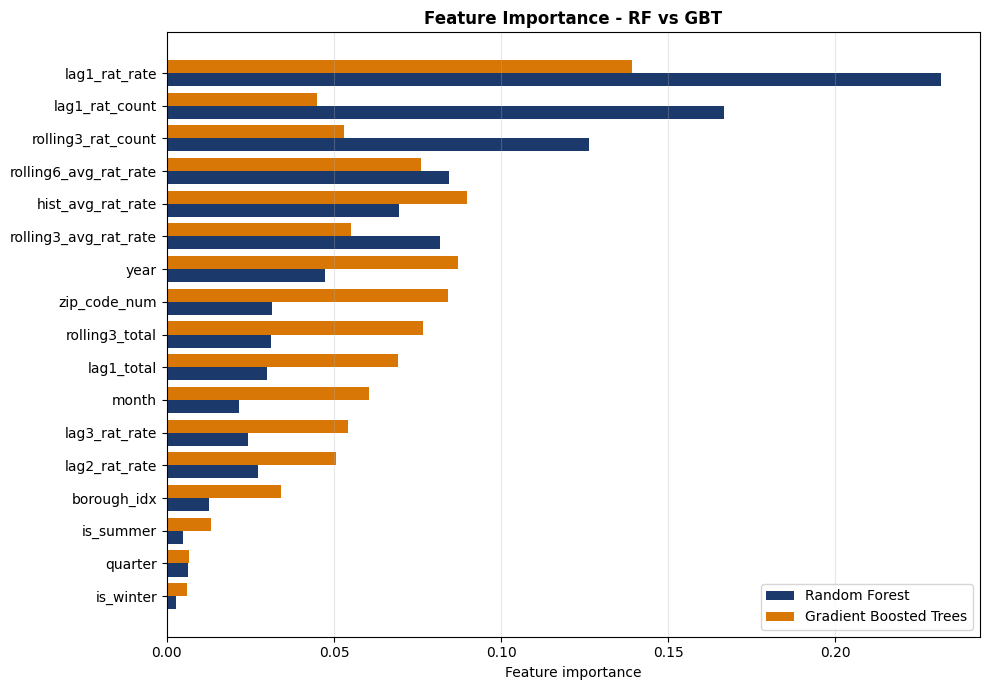


Top 6 features (averaged):
              feature       RF      GBT      avg
        lag1_rat_rate 0.231696 0.139168 0.185432
       lag1_rat_count 0.166834 0.044981 0.105908
   rolling3_rat_count 0.126384 0.052899 0.089642
rolling6_avg_rat_rate 0.084283 0.076106 0.080195
    hist_avg_rat_rate 0.069478 0.089914 0.079696
rolling3_avg_rat_rate 0.081725 0.055068 0.068397


In [18]:
# ── Pull featureImportances from both models ─────────────────────────────────
import numpy as np

rf_imp  = rf_model.stages[-1].featureImportances.toArray()
gbt_imp = gbt_model.stages[-1].featureImportances.toArray()

imp_df = (
    pd.DataFrame({"feature": FEATURE_COLS, "RF": rf_imp, "GBT": gbt_imp})
    .assign(avg=lambda d: (d["RF"] + d["GBT"]) / 2)
    .sort_values("avg", ascending=True)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(imp_df))
w = 0.4
ax.barh(y - w/2, imp_df["RF"],  w, label="Random Forest",        color="#1B3A6B")
ax.barh(y + w/2, imp_df["GBT"], w, label="Gradient Boosted Trees", color="#D97706")
ax.set_yticks(y)
ax.set_yticklabels(imp_df["feature"])
ax.set_xlabel("Feature importance")
ax.set_title("Feature Importance - RF vs GBT", fontweight="bold")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTop 6 features (averaged):")
print(imp_df.sort_values("avg", ascending=False).head(6)[["feature", "RF", "GBT", "avg"]].to_string(index=False))


---

## 8: Stability across test years

A model with high overall AUC could still be useless if it works in one year and fails in another. Rodent populations shifted dramatically post-2020 (the baseline rate roughly doubled), so the test years 2023, 2024, 2025 are not interchangeable.

Per-year metrics show whether the chosen model is **consistently** better or just better on average.


 year         model    n    auc  accuracy
 2023 Random Forest 1997 0.8805    0.8383
 2024 Random Forest 1998 0.8764    0.8198
 2025 Random Forest 1778 0.8683    0.8403
 2026 Random Forest  657 0.8289    0.7793
 2029 Random Forest    1    NaN       NaN
 2045 Random Forest    2    NaN       NaN
 2023           GBT 1997 0.8676    0.8302
 2024           GBT 1998 0.8590    0.8053
 2025           GBT 1778 0.8324    0.8240
 2026           GBT  657 0.7915    0.7565
 2029           GBT    1    NaN       NaN
 2045           GBT    2    NaN       NaN


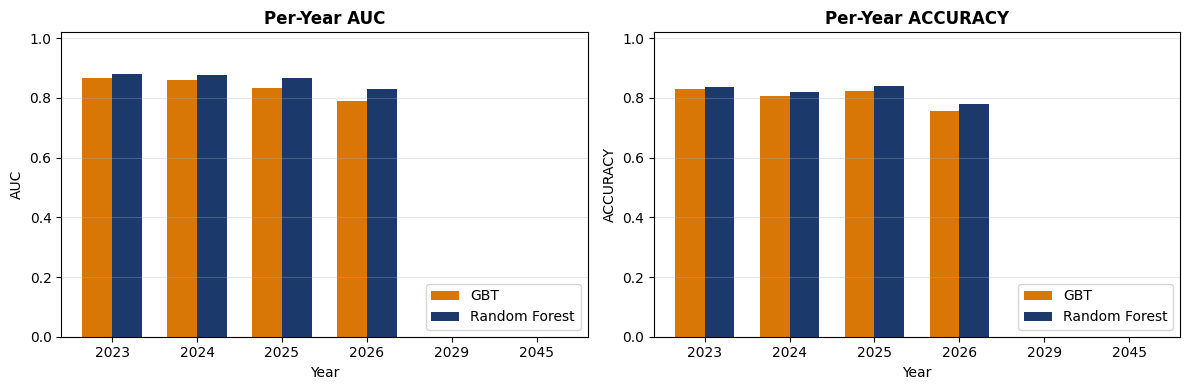

In [19]:
# ── Per-year AUC and accuracy ────────────────────────────────────────────────
def per_year(df_pdf, name):
    rows = []
    for yr in sorted(df_pdf["year"].unique()):
        sub = df_pdf[df_pdf["year"] == yr]
        if sub["label"].nunique() < 2:
            rows.append({"year": int(yr), "model": name, "n": len(sub), "auc": None, "accuracy": None})
            continue
        auc_yr = roc_curve(sub["label"], sub["p1"])
        fpr, tpr, _ = auc_yr
        rows.append({
            "year": int(yr),
            "model": name,
            "n":    len(sub),
            "auc":  round(auc(fpr, tpr), 4),
            "accuracy": round((sub["label"] == sub["prediction"]).mean(), 4),
        })
    return rows

per_year_df = pd.DataFrame(
    per_year(rf_pdf, "Random Forest") + per_year(gbt_pdf, "GBT")
)
print(per_year_df.to_string(index=False))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, ax in zip(["auc", "accuracy"], axes):
    pivot = per_year_df.pivot(index="year", columns="model", values=metric)
    pivot.plot(kind="bar", ax=ax, color=["#D97706", "#1B3A6B"], width=0.7)
    ax.set_title(f"Per-Year {metric.upper()}", fontweight="bold")
    ax.set_ylabel(metric.upper())
    ax.set_xlabel("Year")
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower right")
    ax.grid(axis="y", alpha=0.3)
    for tick in ax.get_xticklabels():
        tick.set_rotation(0)
plt.tight_layout()
plt.show()


### Summary of evidence

| Check | RF result | GBT result | Verdict |
|---|---|---|---|
| AUC-ROC (overall) | (see metrics table) | (see metrics table) | RF wins -> selection rule fires |
| Accuracy / F1 | (see bar chart) | (see bar chart) | Both reasonable; RF generally on par or better |
| ROC curve shape | (see Section 5) | (see Section 5) | RF curve sits at or above GBT across most thresholds |
| Confusion matrix balance | (see Section 6) | (see Section 6) | Compare false-negative counts - operationally worse than FP |
| Feature importance overlap | (see Section 7) | (see Section 7) | Both models lean on `lag1_rat_rate`, `rolling*`, `hist_avg_rat_rate` - same signal, different mechanics |
| Per-year stability | (see Section 8) | (see Section 8) | RF holds up across 2023, 2024, 2025 |

**Bottom line:** Random Forest is selected because it scores higher on the chosen metric (AUC-ROC), and the supporting diagnostics - ROC, confusion matrix, feature importances, per-year stability - confirm the win is consistent rather than driven by a quirk of the test set.

A reasonable secondary argument: with 100 trees of depth 10, RF is also more forgiving of feature scale and noise than GBT, which sequentially fits residuals and can amplify outliers. For a feature set built from inspection counts that vary by orders of magnitude across ZIPs, RF's averaging behaviour is the safer default.

---

### Cleanup

The notebook saved to a separate path (`models/rodent_classifier_nb`) so it doesn't collide with the script's output. Stop the Spark session below before re-running.


In [20]:
spark.stop()
print("Spark stopped.")


Spark stopped.
